# LR tune → locked LRs for the bake-off

Dense **full-optimizer** learning-rate grid on the same model/data as `study_converged_flops.ipynb`, at a **shorter FLOP budget**, then export winners to relock and rerun the bake-off.

**Protocol**
1. Sweep a wide log-spaced LR grid per opt (`adamw` / `soap` / `muon`).
2. Each trial is FLOP-matched to `AdamW × TUNE_REF_STEPS`.
3. Pick LR by **late-window mean val** (not best-ever spike).
4. Write `plots/study/locked_lr.json` + copy-paste `LOCKED_LR` for the bake-off.
5. Zip artifacts to Google Drive.

| Section | Purpose |
|---------|---------|
| **A** | Install + config |
| **B** | Library |
| **C** | FLOP trainer |
| **D** | Data |
| **E** | Budget calibration |
| **F** | LR grid runs |
| **G** | Plots + export |
| **H** | Save to Drive |

`MODE="vet"` = tiny local smoke. `MODE="colab"` = FineWeb tune on GPU.

**Colab:** Runtime → GPU (T4) → Run All. Config print must show **Estimated trials: 46**.



## A1. Install

Run once. NumPy import error → **Runtime → Restart session**, then Run All.



In [ ]:
%pip install -q datasets tiktoken tqdm heavyball matplotlib


## A2. Config

**Edit this cell only** if needed, then Run All.

Config must print `Estimated trials: 46` on Colab.



In [ ]:
# ===================== EDIT ME =====================
MODE = "colab"                 # "vet" | "colab"
FORCE_SYNTHETIC = None
SEED = 42
RESET_DATA = False             # True only to wipe shards; otherwise 30M shard is reused
RESUME = True                  # skip finished (opt, lr); new grid points still run

# Bake-off uses REF_STEPS=5000; tune uses a shorter matched budget
REF_OPT = "adamw"
TUNE_REF_STEPS = 1000          # ~20% of bake-off
FLOP_BUDGET = None

TUNE_OPTS = ["adamw", "soap", "muon"]

import numpy as np
# Thorough edge-aware grids (first narrow pass put soap on HIGH edge, muon on LOW edge)
LR_GRIDS = {
    "adamw":   list(np.geomspace(5e-5, 3e-3, 14)),
    "soap":    list(np.geomspace(3e-4, 3e-2, 16)),
    "muon":    list(np.geomspace(5e-4, 5e-2, 16)),
    "sgd":     list(np.geomspace(1e-2, 5e-1, 10)),
    "shampoo": list(np.geomspace(1e-3, 5e-2, 10)),
}

SELECTION = "late_mean"        # use this to LOCK (not "best")
LATE_K = 3

FALLBACK_LR = {
    "adamw":   3e-4,
    "sgd":     1e-1,
    "muon":    2e-2,
    "soap":    1e-3,
    "shampoo": 1e-2,
}

CALIB_WARMUP = 1
CALIB_MEASURE = 3
# ===================================================

import math
import shutil
import torch
from pathlib import Path


if MODE == "colab":
    if FORCE_SYNTHETIC is None:
        FORCE_SYNTHETIC = False
    # Keep identical to study_converged_flops.ipynb so LRs transfer
    N_LAYER, N_HEAD, N_EMBD, BLOCK, BS = 6, 4, 256, 256, 16
    TOKEN_BUDGET, VAL_TOKENS = 30_000_000, 50_000
    REF_STEPS = TUNE_REF_STEPS
    CFG = dict(
        token_budget=TOKEN_BUDGET, val_tokens=VAL_TOKENS,
        n_layer=N_LAYER, n_head=N_HEAD, n_embd=N_EMBD, block_size=BLOCK,
        batch_size=BS, steps=REF_STEPS,
        eval_every=max(50, REF_STEPS // 20),
        split_at=2,
        combo_search="locked",
        force_synthetic=FORCE_SYNTHETIC,
        device="cuda" if torch.cuda.is_available() else "cpu",
    )
    if CFG["device"] != "cuda":
        print("WARNING: no CUDA — Colab LR tune on CPU is impractical.")
else:
    if FORCE_SYNTHETIC is None:
        FORCE_SYNTHETIC = True
    TUNE_REF_STEPS = 30
    REF_STEPS = TUNE_REF_STEPS
    TUNE_OPTS = ["adamw", "soap", "muon"]
    LR_GRIDS = {
        "adamw":   [1e-4, 3e-4, 1e-3],
        "soap":    [3e-4, 1e-3, 3e-3],
        "muon":    [5e-3, 2e-2, 5e-2],
        "sgd":     [1e-1],
        "shampoo": [1e-2],
    }
    LATE_K = 2
    N_LAYER, N_HEAD, N_EMBD, BLOCK, BS = 4, 2, 64, 64, 8
    CFG = dict(
        token_budget=20_000, val_tokens=2_000,
        n_layer=N_LAYER, n_head=N_HEAD, n_embd=N_EMBD, block_size=BLOCK,
        batch_size=BS, steps=REF_STEPS,
        eval_every=10,
        split_at=2,
        combo_search="locked",
        force_synthetic=True,
        device="cpu",
    )

CALIB_LR = FALLBACK_LR[REF_OPT]

assert set(TUNE_OPTS) <= set(LR_GRIDS)
assert SELECTION in ("late_mean", "final", "best")

if RESET_DATA:
    d = Path("./data/fineweb_edu")
    if d.exists():
        shutil.rmtree(d)
        print("removed", d)

_vocab = 50257
_block = 12 * CFG["n_embd"] ** 2
_approx = _vocab * CFG["n_embd"] + CFG["n_layer"] * _block + CFG["block_size"] * CFG["n_embd"]
_tokens = CFG["batch_size"] * CFG["block_size"] * REF_STEPS
n_trials = sum(len(LR_GRIDS[o]) for o in TUNE_OPTS)

print("MODE:", MODE)
print("device:", CFG["device"])
print(f"model: ~{CFG['n_layer']}L / {CFG['n_head']}H / {CFG['n_embd']}d / T={CFG['block_size']}")
print(f"approx params (tied embed): {_approx/1e6:.1f}M")
print(f"token shard: {CFG['token_budget']:,} (val {CFG['val_tokens']:,})")
print(f"TUNE_REF_STEPS={TUNE_REF_STEPS} → ~{_tokens/1e6:.1f}M tokens seen for AdamW (order-of-mag)")
print("SELECTION:", SELECTION, " LATE_K:", LATE_K)
print(f"\nTUNE_OPTS ({len(TUNE_OPTS)}):", TUNE_OPTS)
for o in TUNE_OPTS:
    gs = LR_GRIDS[o]
    print(f"  {o}: {len(gs)} LRs  [{gs[0]:.3g} … {gs[-1]:.3g}]")
print(f"Estimated trials: {n_trials}")
assert n_trials == 46 or MODE != "colab", "colab thorough grid should be 46 trials"
print("config:")
for k, v in CFG.items():
    print(f"  {k}: {v}")


MODE: colab
device: cuda
model: ~6L / 4H / 256d / T=256
approx params (tied embed): 17.6M
token shard: 30,000,000 (val 50,000)
TUNE_REF_STEPS=1000 → ~4.1M tokens seen for AdamW (order-of-mag)
SELECTION: late_mean  LATE_K: 3

TUNE_OPTS (3): ['adamw', 'soap', 'muon']
  adamw: 14 LRs  [5e-05 … 0.003]
  soap: 16 LRs  [0.0003 … 0.03]
  muon: 16 LRs  [0.0005 … 0.05]
Estimated trials: 46
config:
  token_budget: 30000000
  val_tokens: 50000
  n_layer: 6
  n_head: 4
  n_embd: 256
  block_size: 256
  batch_size: 16
  steps: 1000
  eval_every: 50
  split_at: 2
  combo_search: locked
  force_synthetic: False
  device: cuda


## B. Library



In [ ]:
from __future__ import annotations
import math, time, json
from pathlib import Path
from dataclasses import dataclass
from typing import Iterable

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import AdamW, SGD, Optimizer

DATA_DIR = Path("./data/fineweb_edu")
OUT_DIR = Path("./plots/study")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# -------------------- GPT --------------------
@dataclass
class GPTConfig:
    vocab_size: int = 50257
    block_size: int = 64
    n_layer: int = 4
    n_head: int = 2
    n_embd: int = 64
    dropout: float = 0.0
    bias: bool = False

class CausalSelfAttention(nn.Module):
    def __init__(self, cfg: GPTConfig):
        super().__init__()
        assert cfg.n_embd % cfg.n_head == 0
        self.n_head, self.n_embd = cfg.n_head, cfg.n_embd
        self.head_dim = cfg.n_embd // cfg.n_head
        self.qkv = nn.Linear(cfg.n_embd, 3 * cfg.n_embd, bias=cfg.bias)
        self.proj = nn.Linear(cfg.n_embd, cfg.n_embd, bias=cfg.bias)
        self.attn_drop = nn.Dropout(cfg.dropout)
        self.resid_drop = nn.Dropout(cfg.dropout)
        mask = torch.tril(torch.ones(cfg.block_size, cfg.block_size))
        self.register_buffer("mask", mask.view(1, 1, cfg.block_size, cfg.block_size))

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(self.n_embd, dim=2)
        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(self.head_dim))
        att = att.masked_fill(self.mask[:, :, :T, :T] == 0, float("-inf"))
        att = self.attn_drop(F.softmax(att, dim=-1))
        y = (att @ v).transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_drop(self.proj(y))

class MLP(nn.Module):
    def __init__(self, cfg: GPTConfig):
        super().__init__()
        self.fc = nn.Linear(cfg.n_embd, 4 * cfg.n_embd, bias=cfg.bias)
        self.proj = nn.Linear(4 * cfg.n_embd, cfg.n_embd, bias=cfg.bias)
        self.drop = nn.Dropout(cfg.dropout)
    def forward(self, x):
        return self.drop(self.proj(F.gelu(self.fc(x), approximate="tanh")))

class Block(nn.Module):
    def __init__(self, cfg: GPTConfig):
        super().__init__()
        self.ln1, self.attn = nn.LayerNorm(cfg.n_embd), CausalSelfAttention(cfg)
        self.ln2, self.mlp = nn.LayerNorm(cfg.n_embd), MLP(cfg)
    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        return x + self.mlp(self.ln2(x))

class GPT(nn.Module):
    def __init__(self, cfg: GPTConfig):
        super().__init__()
        self.cfg = cfg
        self.wte = nn.Embedding(cfg.vocab_size, cfg.n_embd)
        self.wpe = nn.Embedding(cfg.block_size, cfg.n_embd)
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layer)])
        self.ln_f = nn.LayerNorm(cfg.n_embd)
        self.lm_head = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False)
        self.wte.weight = self.lm_head.weight
        self.apply(self._init)
        for pn, p in self.named_parameters():
            if pn.endswith("proj.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * cfg.n_layer))

    def _init(self, m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, 0.0, 0.02)
            if m.bias is not None: nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, 0.0, 0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device)
        x = self.drop(self.wte(idx) + self.wpe(pos))
        for blk in self.blocks:
            x = blk(x)
        logits = self.lm_head(self.ln_f(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    def forward_with_block_outs(self, idx):
        """Return final logits and list of post-block hidden states (for spectra)."""
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device)
        x = self.drop(self.wte(idx) + self.wpe(pos))
        outs = []
        for blk in self.blocks:
            x = blk(x)
            outs.append(x)
        logits = self.lm_head(self.ln_f(x))
        return logits, outs

# -------------------- Optimizers --------------------
class CompositeOptimizer:
    def __init__(self, optimizers, name="Composite"):
        self.optimizers, self.name = list(optimizers), name
    def zero_grad(self, set_to_none=True):
        for o in self.optimizers: o.zero_grad(set_to_none=set_to_none)
    def step(self, closure=None):
        for o in self.optimizers: o.step()
    def __repr__(self):
        return f"{self.name}(" + ", ".join(type(o).__name__ for o in self.optimizers) + ")"

def unique_params(model):
    seen, out = set(), []
    for p in model.parameters():
        if p.requires_grad and id(p) not in seen:
            seen.add(id(p)); out.append(p)
    return out

def make_optimizer(name, params, lr):
    name, params = name.lower(), list(params)
    if name == "adamw":
        return AdamW(params, lr=lr, betas=(0.9, 0.95), weight_decay=0.1)
    if name == "sgd":
        return SGD(params, lr=lr, momentum=0.9)
    if name == "muon":
        m2 = [p for p in params if p.ndim >= 2]
        m1 = [p for p in params if p.ndim < 2]
        opts = []
        if m2: opts.append(torch.optim.Muon(m2, lr=lr, weight_decay=0.1, momentum=0.95))
        if m1: opts.append(AdamW(m1, lr=min(lr, 3e-4) if lr > 1e-3 else lr, betas=(0.9, 0.95), weight_decay=0.1))
        return opts[0] if len(opts) == 1 else CompositeOptimizer(opts, "Muon+AdamW")
    if name in ("soap", "shampoo"):
        import heavyball
        kw = dict(lr=lr, weight_decay=0.01, compile_step=False, betas=(0.9, 0.95))
        return heavyball.SOAP(params, **kw) if name == "soap" else heavyball.KLShampoo(params, **kw)
    raise ValueError(name)

def split_param_groups(model, split_at):
    n = model.cfg.n_layer
    assert 0 < split_at < n
    bottom, top, seen = [], [], set()
    def add(g, ps):
        for p in ps:
            if id(p) not in seen:
                seen.add(id(p)); g.append(p)
    add(bottom, model.wte.parameters()); add(bottom, model.wpe.parameters())
    for b in model.blocks[:split_at]: add(bottom, b.parameters())
    for b in model.blocks[split_at:]: add(top, b.parameters())
    add(top, model.ln_f.parameters()); add(top, model.lm_head.parameters())
    return bottom, top

def build_full_optimizer(model, name, lr):
    return make_optimizer(name, unique_params(model), lr)

def build_split_optimizers(model, split_at, bottom_opt, top_opt, bottom_lr, top_lr):
    b, t = split_param_groups(model, split_at)
    return make_optimizer(bottom_opt, b, bottom_lr), make_optimizer(top_opt, t, top_lr)

def all_split_combos():
    return [(a, b) for a in OPTS for b in OPTS]

# -------------------- Data --------------------
def ensure_data(cfg):
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    tr_path, va_path = DATA_DIR / "train.bin", DATA_DIR / "val.bin"

    def write(tokens, val_n):
        tokens[:val_n].tofile(va_path)
        tokens[val_n:].tofile(tr_path)
        print(f"[data] train={tr_path} ({len(tokens)-val_n:,})  val={va_path} ({val_n:,})")

    def shards_ok():
        if not (tr_path.exists() and va_path.exists()):
            return False
        need = cfg["token_budget"] - cfg["val_tokens"]
        tr = np.memmap(tr_path, dtype=np.uint16, mode="r")
        va = np.memmap(va_path, dtype=np.uint16, mode="r")
        ok = len(tr) >= need and len(va) >= min(cfg["val_tokens"], need // 10)
        del tr, va
        return ok

    if cfg["force_synthetic"]:
        import tiktoken
        enc = tiktoken.get_encoding("gpt2")
        eot = enc._special_tokens["<|endoftext|>"]
        text = ("Transformers predict the next token. Early layers mix local syntax; "
                "deeper layers carry longer-range semantics. Optimizers shape updates.")
        ids = []
        while len(ids) < cfg["token_budget"]:
            ids.extend(enc.encode_ordinary(text)); ids.append(eot)
        write(np.array(ids[:cfg["token_budget"]], dtype=np.uint16), cfg["val_tokens"])
        print("[data] SYNTHETIC (vet only — not for the write-up)")
    elif shards_ok():
        print(f"[data] Reusing existing shards in {DATA_DIR} "
              f"(train>={cfg['token_budget']-cfg['val_tokens']:,})")
    else:
        import tiktoken
        from datasets import load_dataset
        from tqdm.auto import tqdm
        enc = tiktoken.get_encoding("gpt2")
        eot = enc._special_tokens["<|endoftext|>"]
        print(f"[data] FineWeb-Edu → {cfg['token_budget']:,} tokens...")
        ds = load_dataset("HuggingFaceFW/fineweb-edu", name="sample-10BT", split="train", streaming=True)
        ds = ds.shuffle(seed=SEED, buffer_size=10_000)
        tokens = np.empty(cfg["token_budget"], dtype=np.uint16)
        n = 0
        pbar = tqdm(total=cfg["token_budget"], unit="tok")
        for row in ds:
            text = row.get("text") or ""
            if not text.strip(): continue
            for tok in enc.encode_ordinary(text) + [eot]:
                tokens[n] = tok; n += 1; pbar.update(1)
                if n >= cfg["token_budget"]: break
            if n >= cfg["token_budget"]: break
        pbar.close()
        assert n == cfg["token_budget"]
        write(tokens, cfg["val_tokens"])

    train = np.asarray(np.memmap(tr_path, dtype=np.uint16, mode="r"))
    val = np.asarray(np.memmap(va_path, dtype=np.uint16, mode="r"))
    max_tr = cfg["token_budget"] - cfg["val_tokens"]
    return train[:max_tr], val[:cfg["val_tokens"]]

# -------------------- Train --------------------
def get_batch(data, bs, T, device, g):
    ix = torch.randint(0, len(data) - T - 1, (bs,), generator=g)
    x = torch.stack([torch.from_numpy(data[i:i+T].astype(np.int64)) for i in ix])
    y = torch.stack([torch.from_numpy(data[i+1:i+1+T].astype(np.int64)) for i in ix])
    return x.to(device), y.to(device)

@torch.no_grad()
def eval_val(model, val, bs, T, device, iters=32):
    model.eval()
    g = torch.Generator().manual_seed(0)
    losses = []
    for _ in range(iters):
        xb, yb = get_batch(val, bs, T, device, g)
        _, loss = model(xb, yb)
        losses.append(loss.item())
    model.train()
    return float(np.mean(losses))

def make_model(cfg):
    return GPT(GPTConfig(
        block_size=cfg["block_size"], n_layer=cfg["n_layer"],
        n_head=cfg["n_head"], n_embd=cfg["n_embd"],
    )).to(cfg["device"])

def train_full(cfg, train, val, opt_name, lr, seed=SEED):
    torch.manual_seed(seed); g = torch.Generator().manual_seed(seed)
    model = make_model(cfg)
    opt = build_full_optimizer(model, opt_name, lr)
    hist = {"step": [], "val": [], "train": []}
    t0 = time.time(); last = float("nan")
    for step in range(1, cfg["steps"] + 1):
        xb, yb = get_batch(train, cfg["batch_size"], cfg["block_size"], cfg["device"], g)
        opt.zero_grad(set_to_none=True)
        _, loss = model(xb, yb); loss.backward(); opt.step()
        last = loss.item()
        if step == 1 or step % cfg["eval_every"] == 0 or step == cfg["steps"]:
            v = eval_val(model, val, cfg["batch_size"], cfg["block_size"], cfg["device"])
            hist["step"].append(step); hist["val"].append(v); hist["train"].append(last)
    return {"opt": opt_name, "lr": lr, "final_val": hist["val"][-1], "best_val": min(hist["val"]),
            "history": hist, "seconds": time.time()-t0, "model": model}

def train_split(cfg, train, val, b_opt, t_opt, b_lr, t_lr, seed=SEED):
    torch.manual_seed(seed); g = torch.Generator().manual_seed(seed)
    model = make_model(cfg)
    opt_b, opt_t = build_split_optimizers(model, cfg["split_at"], b_opt, t_opt, b_lr, t_lr)
    hist = {"step": [], "val": [], "train": []}
    t0 = time.time(); last = float("nan")
    for step in range(1, cfg["steps"] + 1):
        xb, yb = get_batch(train, cfg["batch_size"], cfg["block_size"], cfg["device"], g)
        opt_b.zero_grad(set_to_none=True); opt_t.zero_grad(set_to_none=True)
        _, loss = model(xb, yb); loss.backward(); opt_b.step(); opt_t.step()
        last = loss.item()
        if step == 1 or step % cfg["eval_every"] == 0 or step == cfg["steps"]:
            v = eval_val(model, val, cfg["batch_size"], cfg["block_size"], cfg["device"])
            hist["step"].append(step); hist["val"].append(v); hist["train"].append(last)
    return {"bottom_opt": b_opt, "top_opt": t_opt, "bottom_lr": b_lr, "top_lr": t_lr,
            "final_val": hist["val"][-1], "best_val": min(hist["val"]),
            "history": hist, "seconds": time.time()-t0, "model": model}

print("Library ready.")


Library ready.


## C. FLOP meter + train-until-budget



In [ ]:
from collections import defaultdict
from contextlib import contextmanager
from torch.utils._python_dispatch import TorchDispatchMode
from torch.utils.flop_counter import FlopCounterMode


def _numel_from_args(args, kwargs):
    n = 0
    for a in args:
        if torch.is_tensor(a):
            n = max(n, a.numel())
    for a in (kwargs or {}).values():
        if torch.is_tensor(a):
            n = max(n, a.numel())
    return n


def _matmul_flops(a, b):
    if a.ndim < 2 or b.ndim < 2:
        return 0
    M, K = a.shape[-2], a.shape[-1]
    N = b.shape[-1]
    batch = 1
    for d in a.shape[:-2]:
        batch *= d
    return int(batch * 2 * M * N * K)


class PointwiseFlopMode(TorchDispatchMode):
    def __init__(self):
        super().__init__()
        self.flops = 0
        self.by_op = defaultdict(int)

    def __torch_dispatch__(self, func, types, args=(), kwargs=None):
        kwargs = kwargs or {}
        out = func(*args, **kwargs)
        raw = getattr(func, "__name__", str(func))
        if hasattr(func, "name"):
            try:
                raw = func.name()
            except Exception:
                pass
        name = raw.split("::")[-1]
        base = name.split(".")[0]
        fl = 0
        tensors = [a for a in args if torch.is_tensor(a)]
        if base in ("mm", "matmul", "bmm"):
            if len(tensors) >= 2:
                fl = _matmul_flops(tensors[0], tensors[1])
        elif base in ("addmm", "baddbmm"):
            if len(tensors) >= 3:
                fl = _matmul_flops(tensors[1], tensors[2])
        elif base in (
            "add", "add_", "sub", "sub_", "mul", "mul_", "div", "div_",
            "pow", "pow_", "neg", "neg_", "sqrt", "rsqrt", "exp", "log",
            "lerp", "lerp_", "clamp", "clamp_", "where",
        ):
            fl = _numel_from_args(args, kwargs)
        elif base in ("addcdiv", "addcdiv_", "addcmul", "addcmul_"):
            fl = 3 * _numel_from_args(args, kwargs)
        if fl:
            self.flops += int(fl)
            self.by_op[base] += int(fl)
        return out


def _as_opt_list(opt):
    if isinstance(opt, list):
        out = []
        for o in opt:
            out.extend(_as_opt_list(o))
        return out
    if hasattr(opt, "optimizers") and isinstance(getattr(opt, "optimizers"), list):
        return list(opt.optimizers)
    return [opt]


def measure_train_step_flops(model, opt, idx, targets):
    if hasattr(opt, "zero_grad") and not isinstance(opt, list):
        opt.zero_grad(set_to_none=True)
        opts_for_step = opt
    else:
        opts = _as_opt_list(opt)
        for o in opts:
            o.zero_grad(set_to_none=True)
        opts_for_step = opts

    model.train()
    with FlopCounterMode(display=False) as fc:
        _, loss = model(idx, targets)
        loss.backward()
    fwd_bwd = int(fc.get_total_flops())

    mode = PointwiseFlopMode()
    with mode:
        if isinstance(opts_for_step, list):
            for o in opts_for_step:
                o.step()
        else:
            opts_for_step.step()
    opt_flops = int(mode.flops)
    total = fwd_bwd + opt_flops
    return {
        "fwd_bwd_flops": fwd_bwd,
        "opt_flops": opt_flops,
        "total_flops": total,
        "opt_share": opt_flops / total if total else 0.0,
        "loss": float(loss.detach()),
        "opt_by_op": dict(sorted(mode.by_op.items(), key=lambda kv: -kv[1])[:12]),
    }


def _build_opt_bundle(model, kind, opt_name=None, lr=None, bottom_opt=None, top_opt=None,
                      bottom_lr=None, top_lr=None, split_at=None):
    if kind == "full":
        opt = build_full_optimizer(model, opt_name, lr)
        return opt, opt
    opt_b, opt_t = build_split_optimizers(
        model, split_at=split_at, bottom_opt=bottom_opt, top_opt=top_opt,
        bottom_lr=bottom_lr, top_lr=top_lr,
    )
    return [opt_b, opt_t], CompositeOptimizer([opt_b, opt_t], "split")


def calibrate_step_flops(model, opt, train, cfg, g, warmup=1, measure=3):
    """Run warmup + measure steps. Return steady-state FLOPs/step and per-step logs."""
    logs = []
    for i in range(warmup + measure):
        xb, yb = get_batch(train, cfg["batch_size"], cfg["block_size"], cfg["device"], g)
        stats = measure_train_step_flops(model, opt, xb, yb)
        stats["calib_i"] = i
        logs.append(stats)
    steady = logs[warmup:]
    per_step = float(np.mean([s["total_flops"] for s in steady]))
    opt_share = float(np.mean([s["opt_share"] for s in steady]))
    return {
        "flops_per_step": per_step,
        "opt_share": opt_share,
        "fwd_bwd": float(np.mean([s["fwd_bwd_flops"] for s in steady])),
        "opt_flops": float(np.mean([s["opt_flops"] for s in steady])),
        "logs": logs,
    }


@torch.no_grad()
def _eval(model, val, cfg):
    return eval_val(model, val, cfg["batch_size"], cfg["block_size"], cfg["device"])


def train_until_flops(
    cfg, train, val, flop_budget, *,
    kind="full",
    opt_name=None, lr=None,
    bottom_opt=None, top_opt=None, bottom_lr=None, top_lr=None,
    seed=SEED,
    calib_warmup=CALIB_WARMUP,
    calib_measure=CALIB_MEASURE,
    label="run",
):
    """
    Train until cumulative FLOPs >= flop_budget.
    Warmup+measure steps are real training and count toward the budget.
    Steady-state FLOPs/step is the mean of the measure window (warmup excluded from that mean only).
    """
    torch.manual_seed(seed)
    g = torch.Generator().manual_seed(seed)
    model = make_model(cfg)
    opt, opt_for_zero = _build_opt_bundle(
        model, kind, opt_name=opt_name, lr=lr,
        bottom_opt=bottom_opt, top_opt=top_opt,
        bottom_lr=bottom_lr, top_lr=top_lr,
        split_at=cfg["split_at"],
    )

    t0 = time.time()
    calib = calibrate_step_flops(
        model, opt, train, cfg, g, warmup=calib_warmup, measure=calib_measure
    )
    flops_per_step = calib["flops_per_step"]
    # charge calibration steps at their measured totals
    cum = float(sum(s["total_flops"] for s in calib["logs"]))
    steps_done = len(calib["logs"])
    last_train = float(calib["logs"][-1]["loss"])

    hist = {"step": [], "val": [], "train": [], "flops": []}
    def record():
        v = _eval(model, val, cfg)
        hist["step"].append(steps_done)
        hist["val"].append(v)
        hist["train"].append(last_train)
        hist["flops"].append(cum)
        return v

    record()
    eval_every = cfg["eval_every"]
    max_steps = int(flop_budget / max(flops_per_step, 1)) + calib_warmup + calib_measure + 5

    while cum < flop_budget and steps_done < max_steps:
        xb, yb = get_batch(train, cfg["batch_size"], cfg["block_size"], cfg["device"], g)
        if hasattr(opt_for_zero, "zero_grad"):
            opt_for_zero.zero_grad(set_to_none=True)
        else:
            for o in _as_opt_list(opt):
                o.zero_grad(set_to_none=True)
        _, loss = model(xb, yb)
        loss.backward()
        if isinstance(opt, list):
            for o in opt:
                o.step()
        else:
            opt.step()
        last_train = float(loss.item())
        cum += flops_per_step
        steps_done += 1
        if steps_done % eval_every == 0 or cum >= flop_budget:
            record()

    # final eval if last record wasn't at end
    if not hist["step"] or hist["step"][-1] != steps_done:
        record()

    result = {
        "kind": kind,
        "label": label,
        "final_val": hist["val"][-1],
        "best_val": min(hist["val"]),
        "steps": steps_done,
        "flops": cum,
        "flops_per_step": flops_per_step,
        "opt_share": calib["opt_share"],
        "fwd_bwd_per_step": calib["fwd_bwd"],
        "opt_flops_per_step": calib["opt_flops"],
        "history": hist,
        "seconds": time.time() - t0,
        "model": model,
        "calib": {k: calib[k] for k in ("flops_per_step", "opt_share", "fwd_bwd", "opt_flops")},
    }
    if kind == "full":
        result.update({"opt": opt_name, "lr": lr})
    else:
        result.update({
            "bottom_opt": bottom_opt, "top_opt": top_opt,
            "bottom_lr": bottom_lr, "top_lr": top_lr,
        })
    return result

print("FLOP trainer ready.")






FLOP trainer ready.


## D. Data



In [ ]:
train, val = ensure_data(CFG)
print(f"Ready — train={len(train):,}  val={len(val):,}")
assert len(train) > CFG["block_size"] + 1
assert len(val) > CFG["block_size"] + 1
if not CFG["force_synthetic"] and len(train) < 1_000_000:
    print("NOTE: train shard < 1M tokens — for the bake-off you usually want RESET_DATA=True "
          "and token_budget=~30M on Colab.")


[data] FineWeb-Edu → 30,000,000 tokens...


README.md:   0%|          | 0.00/26.4k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/2410 [00:00<?, ?it/s]

  0%|          | 0/30000000 [00:00<?, ?tok/s]

[data] train=data/fineweb_edu/train.bin (29,950,000)  val=data/fineweb_edu/val.bin (50,000)
Ready — train=29,950,000  val=50,000


## E. FLOP budget



In [ ]:
print("=" * 64)
print("BUDGET CALIBRATION (AdamW FLOPs/step × TUNE_REF_STEPS)")
print("=" * 64)

LOCKED_LR = dict(FALLBACK_LR)

if FLOP_BUDGET is None:
    torch.manual_seed(SEED)
    g = torch.Generator().manual_seed(SEED)
    probe = make_model(CFG)
    n_params = sum(p.numel() for p in unique_params(probe))
    print(f"actual unique params: {n_params:,} ({n_params/1e6:.2f}M)")
    probe_opt = build_full_optimizer(probe, REF_OPT, CALIB_LR)
    cal = calibrate_step_flops(
        probe, probe_opt, train, CFG, g,
        warmup=CALIB_WARMUP, measure=CALIB_MEASURE,
    )
    FLOP_BUDGET = cal["flops_per_step"] * TUNE_REF_STEPS
    print(f"REF {REF_OPT}: FLOPs/step={cal['flops_per_step']:.4e}  "
          f"opt_share={100*cal['opt_share']:.2f}%")
    print(f"Tune budget = {cal['flops_per_step']:.4e} × {TUNE_REF_STEPS} = {FLOP_BUDGET:.4e}")
    del probe, probe_opt
else:
    print(f"Using explicit FLOP_BUDGET={FLOP_BUDGET:.4e}")

print(f"\nFLOP_BUDGET = {FLOP_BUDGET:.6e}")
assert FLOP_BUDGET > 0


BUDGET CALIBRATION (AdamW FLOPs/step × TUNE_REF_STEPS)
actual unique params: 17,656,576 (17.66M)
REF adamw: FLOPs/step=4.5148e+11  opt_share=0.00%
Tune budget = 4.5148e+11 × 1000 = 4.5148e+14

FLOP_BUDGET = 4.514812e+14


## F. LR grid runs

Each `(opt, lr)` trains until the tune FLOP budget. Resume-safe via `plots/study/lr_tune_checkpoints.json`.



In [ ]:
print("=" * 64)
print(f"LR TUNE  budget={FLOP_BUDGET:.4e}  opts={TUNE_OPTS}")
print("=" * 64)

CKPT_PATH = OUT_DIR / "lr_tune_checkpoints.json"
if RESUME and CKPT_PATH.exists():
    ckpt = json.loads(CKPT_PATH.read_text())
    print(f"Resuming from {CKPT_PATH} ({len(ckpt.get('trials', []))} trials saved)")
else:
    ckpt = {
        "trials": [],
        "flop_budget": FLOP_BUDGET,
        "tune_ref_steps": TUNE_REF_STEPS,
        "config": CFG,
        "lr_grids": {k: list(map(float, v)) for k, v in LR_GRIDS.items() if k in TUNE_OPTS},
    }


def save_ckpt():
    CKPT_PATH.write_text(json.dumps(ckpt, indent=2))


def trial_key(opt, lr):
    return f"{opt}|{lr:.8g}"


done = {trial_key(t["opt"], t["lr"]) for t in ckpt.get("trials", [])}
trials = list(ckpt.get("trials", []))

for opt in TUNE_OPTS:
    for lr in LR_GRIDS[opt]:
        lr = float(lr)
        key = trial_key(opt, lr)
        if key in done:
            print(f"\n=== {opt} lr={lr:g} (skip, cached) ===")
            continue
        print(f"\n=== {opt} lr={lr:g} ===", flush=True)
        r = train_until_flops(
            CFG, train, val, FLOP_BUDGET,
            kind="full", opt_name=opt, lr=lr, seed=SEED,
            label=f"lr:{opt}:{lr:g}",
        )
        r.pop("model", None)
        if "calib" in r and isinstance(r["calib"], dict):
            r["calib"] = {k: r["calib"][k] for k in
                          ("flops_per_step", "opt_share", "fwd_bwd_flops", "opt_flops")
                          if k in r["calib"]}
        row = {
            "opt": opt,
            "lr": lr,
            "final_val": r["final_val"],
            "best_val": r["best_val"],
            "steps": r["steps"],
            "flops": r["flops"],
            "flops_per_step": r.get("flops_per_step"),
            "opt_share": r.get("opt_share"),
            "seconds": r.get("seconds"),
            "history": r.get("history"),
            "calib": r.get("calib"),
        }
        trials.append(row)
        ckpt["trials"] = trials
        ckpt["flop_budget"] = FLOP_BUDGET
        save_ckpt()
        print(f"  -> final_val={row['final_val']:.4f}  best={row['best_val']:.4f}  "
              f"steps={row['steps']}  opt%={100*(row['opt_share'] or 0):.1f}%")

print(f"\nDone. {len(trials)} trials in {CKPT_PATH}")


LR TUNE  budget=4.5148e+14  opts=['adamw', 'soap', 'muon']

=== adamw lr=5e-05 ===
  -> final_val=6.9116  best=6.9116  steps=1000  opt%=0.0%

=== adamw lr=6.85095e-05 ===
  -> final_val=6.8000  best=6.8000  steps=1000  opt%=0.0%

=== adamw lr=9.38711e-05 ===
  -> final_val=6.7087  best=6.7087  steps=1000  opt%=0.0%

=== adamw lr=0.000128621 ===
  -> final_val=6.6303  best=6.6303  steps=1000  opt%=0.0%

=== adamw lr=0.000176236 ===
  -> final_val=6.5524  best=6.5524  steps=1000  opt%=0.0%

=== adamw lr=0.000241476 ===
  -> final_val=6.4857  best=6.4857  steps=1000  opt%=0.0%

=== adamw lr=0.000330868 ===
  -> final_val=6.4227  best=6.4227  steps=1000  opt%=0.0%

=== adamw lr=0.000453353 ===
  -> final_val=6.3747  best=6.3747  steps=1000  opt%=0.0%

=== adamw lr=0.000621179 ===
  -> final_val=6.3170  best=6.3170  steps=1000  opt%=0.0%

=== adamw lr=0.000851134 ===
  -> final_val=6.6352  best=6.6352  steps=1000  opt%=0.0%

=== adamw lr=0.00116622 ===
  -> final_val=6.5693  best=6.5693  st

## G. Select winners, plots, export

Exports `locked_lr.json`, `lr_tune_summary.json`, and PNGs under `plots/study/`.



SELECT + EXPORT
Loaded 46 trials from plots/study/lr_tune_checkpoints.json

adamw: best lr=0.000621179  score(late_mean)=6.3429  final=6.3170  best=6.3170  [interior]
  top-3:
    lr=0.0006212  score=6.3429  final=6.3170  late=6.3429
    lr=0.0004534  score=6.3940  final=6.3747  late=6.3940
    lr=0.0003309  score=6.4402  final=6.4227  late=6.4402

soap: best lr=0.00257309  score(late_mean)=5.9331  final=5.9102  best=5.9102  [interior]
  top-3:
    lr=0.002573  score=5.9331  final=5.9102  late=5.9331
    lr=0.001893  score=5.9417  final=5.9169  late=5.9417
    lr=0.003498  score=5.9521  final=5.9299  late=5.9521

muon: best lr=0.00582957  score(late_mean)=5.9636  final=5.9334  best=5.9334  [interior]
  top-3:
    lr=0.00583  score=5.9636  final=5.9334  late=5.9636
    lr=0.007924  score=5.9834  final=5.9492  late=5.9834
    lr=0.004288  score=5.9850  final=5.9541  late=5.9850


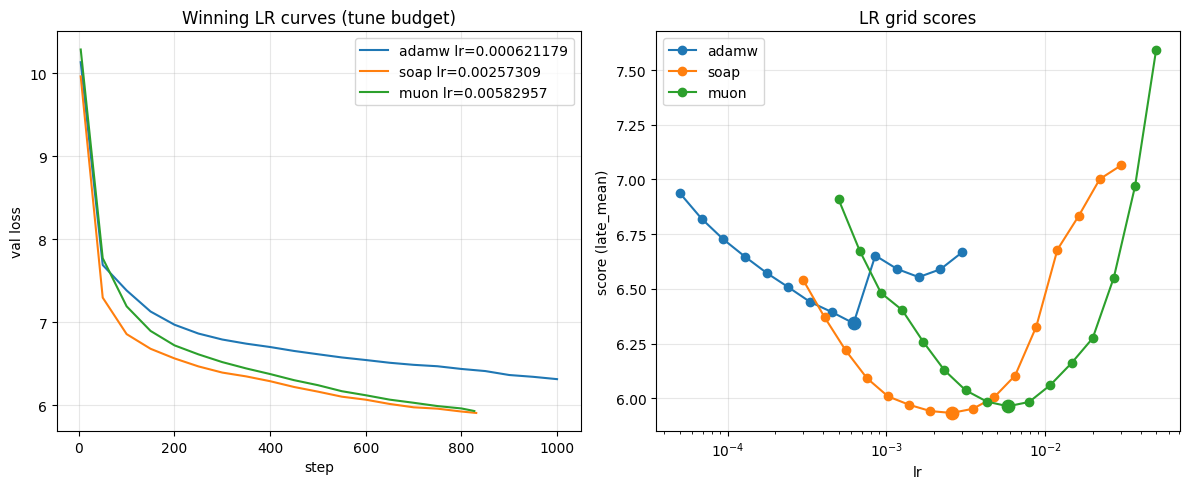

wrote plots/study/lr_tune_curves.png


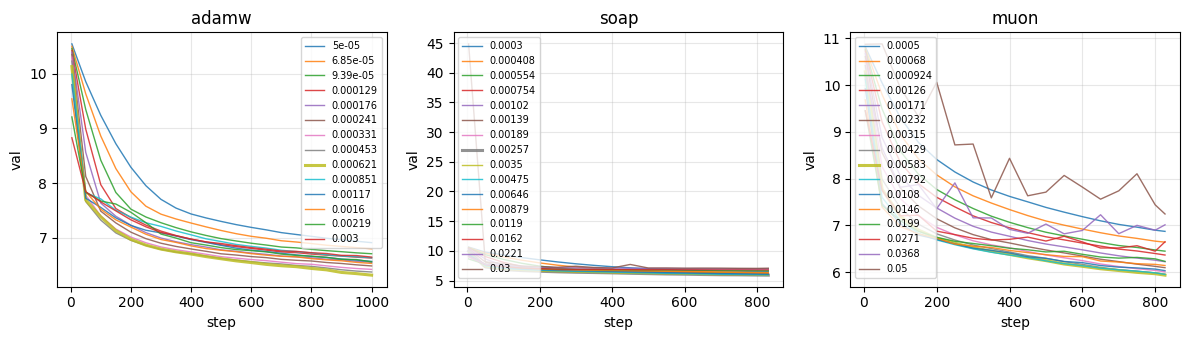

wrote plots/study/lr_tune_grid.png
wrote plots/study/lr_tune_summary.json
wrote plots/study/locked_lr.json

COPY INTO study_converged_flops.ipynb (A2. Config):
LOCKED_LR = {
    "adamw": 0.000621179,
    "muon": 0.00582957,
    "sgd": 0.1,
    "shampoo": 0.01,
    "soap": 0.00257309,
}
Then set RESUME=False (or delete bakeoff_checkpoints.json) and rerun the bake-off.


In [ ]:
from collections import defaultdict

print("=" * 64)
print("SELECT + EXPORT")
print("=" * 64)

# Reload trials from disk if kernel was restarted after the grid finished
CKPT_PATH = OUT_DIR / "lr_tune_checkpoints.json"
if CKPT_PATH.exists():
    _ckpt = json.loads(CKPT_PATH.read_text())
    trials = list(_ckpt.get("trials", []))
    if FLOP_BUDGET is None and _ckpt.get("flop_budget") is not None:
        FLOP_BUDGET = _ckpt["flop_budget"]
    print(f"Loaded {len(trials)} trials from {CKPT_PATH}")
else:
    trials = list(globals().get("trials", []))
    print(f"Using in-memory trials: {len(trials)}")


def history_vals(history):
    """Normalize history → (steps, vals). Format is dict-of-lists."""
    if not history:
        return [], []
    if isinstance(history, dict):
        return list(history.get("step") or []), list(history.get("val") or [])
    if isinstance(history, list):
        steps, vals = [], []
        for h in history:
            if isinstance(h, dict) and h.get("val") is not None:
                steps.append(h.get("step"))
                vals.append(h["val"])
        return steps, vals
    return [], []


def late_mean(history, k=LATE_K):
    _, vals = history_vals(history)
    if not vals:
        return float("inf")
    return float(np.mean(vals[-k:]))


def score_trial(t):
    if SELECTION == "late_mean":
        return late_mean(t.get("history"), LATE_K)
    if SELECTION == "final":
        return float(t["final_val"])
    return float(t["best_val"])


by_opt = defaultdict(list)
for t in trials:
    by_opt[t["opt"]].append(t)

winners = {}
rankings = {}
for opt in TUNE_OPTS:
    rows = sorted(by_opt[opt], key=score_trial)
    rankings[opt] = [
        {
            "lr": r["lr"],
            "score": score_trial(r),
            "final_val": r["final_val"],
            "best_val": r["best_val"],
            "late_mean": late_mean(r.get("history"), LATE_K),
            "steps": r["steps"],
            "opt_share": r.get("opt_share"),
            "seconds": r.get("seconds"),
        }
        for r in rows
    ]
    if not rows:
        print(f"WARNING: no trials for {opt}; keeping FALLBACK_LR")
        winners[opt] = float(FALLBACK_LR[opt])
        continue
    best = rows[0]
    winners[opt] = float(best["lr"])
    lrs = [r["lr"] for r in rows]
    on_lo = abs(winners[opt] - min(lrs)) / max(winners[opt], 1e-12) < 1e-6
    on_hi = abs(winners[opt] - max(lrs)) / max(winners[opt], 1e-12) < 1e-6
    edge = "LOW EDGE" if on_lo else ("HIGH EDGE" if on_hi else "interior")
    print(f"\n{opt}: best lr={best['lr']:g}  "
          f"score({SELECTION})={score_trial(best):.4f}  "
          f"final={best['final_val']:.4f}  best={best['best_val']:.4f}  [{edge}]")
    print("  top-3:")
    for row in rankings[opt][:3]:
        print(f"    lr={row['lr']:.4g}  score={row['score']:.4f}  "
              f"final={row['final_val']:.4f}  late={row['late_mean']:.4f}")

LOCKED_LR = dict(FALLBACK_LR)
LOCKED_LR.update(winners)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ax = axes[0]
for opt in TUNE_OPTS:
    rows = by_opt[opt]
    if not rows:
        continue
    best = min(rows, key=score_trial)
    xs, ys = history_vals(best.get("history"))
    if xs:
        ax.plot(xs, ys, label=f"{opt} lr={best['lr']:g}")
ax.set_xlabel("step"); ax.set_ylabel("val loss")
ax.set_title("Winning LR curves (tune budget)")
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[1]
for opt in TUNE_OPTS:
    rows = sorted(by_opt[opt], key=lambda r: r["lr"])
    if not rows:
        continue
    xs = [r["lr"] for r in rows]
    ys = [score_trial(r) for r in rows]
    ax.plot(xs, ys, marker="o", label=opt)
    ax.scatter([winners[opt]], [min(ys)], s=80, zorder=5)
ax.set_xscale("log"); ax.set_xlabel("lr")
ax.set_ylabel(f"score ({SELECTION})")
ax.set_title("LR grid scores")
ax.legend(); ax.grid(True, alpha=0.3)

fig.tight_layout()
curve_path = OUT_DIR / "lr_tune_curves.png"
fig.savefig(curve_path, dpi=140, bbox_inches="tight")
plt.show()
print("wrote", curve_path)

n = len(TUNE_OPTS)
fig, axes = plt.subplots(1, n, figsize=(4 * n, 3.5), squeeze=False)
for i, opt in enumerate(TUNE_OPTS):
    ax = axes[0][i]
    for r in sorted(by_opt[opt], key=lambda x: x["lr"]):
        xs, ys = history_vals(r.get("history"))
        if not xs:
            continue
        lw = 2.2 if abs(r["lr"] - winners[opt]) / max(winners[opt], 1e-12) < 1e-9 else 1.0
        ax.plot(xs, ys, lw=lw, alpha=0.85, label=f"{r['lr']:.3g}")
    ax.set_title(opt); ax.set_xlabel("step"); ax.set_ylabel("val")
    ax.grid(True, alpha=0.3); ax.legend(fontsize=7, loc="best")
fig.tight_layout()
grid_path = OUT_DIR / "lr_tune_grid.png"
fig.savefig(grid_path, dpi=140, bbox_inches="tight")
plt.show()
print("wrote", grid_path)

export = {
    "study": "lr_tune",
    "selection": SELECTION,
    "late_k": LATE_K,
    "tune_ref_steps": TUNE_REF_STEPS,
    "flop_budget": FLOP_BUDGET,
    "seed": SEED,
    "config": CFG,
    "tune_opts": TUNE_OPTS,
    "winners": winners,
    "locked_lr": LOCKED_LR,
    "fallback_lr": FALLBACK_LR,
    "rankings": rankings,
    "n_trials": len(trials),
}
sum_path = OUT_DIR / "lr_tune_summary.json"
sum_path.write_text(json.dumps(export, indent=2))
print("wrote", sum_path)

lock_path = OUT_DIR / "locked_lr.json"
lock_path.write_text(json.dumps({
    "locked_lr": LOCKED_LR,
    "winners": winners,
    "selection": SELECTION,
    "late_k": LATE_K,
    "tune_ref_steps": TUNE_REF_STEPS,
    "flop_budget": FLOP_BUDGET,
    "seed": SEED,
    "note": "Paste locked_lr into study_converged_flops.ipynb LOCKED_LR, then rerun bake-off.",
}, indent=2))
print("wrote", lock_path)

snippet = "LOCKED_LR = {\n" + "".join(
    f'    "{k}": {LOCKED_LR[k]:.6g},\n' for k in sorted(LOCKED_LR)
) + "}"
print("\n" + "=" * 64)
print("COPY INTO study_converged_flops.ipynb (A2. Config):")
print("=" * 64)
print(snippet)
print("=" * 64)
print("Then set RESUME=False (or delete bakeoff_checkpoints.json) and rerun the bake-off.")
if any(
    abs(winners[o] - min(r["lr"] for r in by_opt[o])) / max(winners[o], 1e-12) < 1e-6
    or abs(winners[o] - max(r["lr"] for r in by_opt[o])) / max(winners[o], 1e-12) < 1e-6
    for o in TUNE_OPTS if by_opt[o]
):
    print("\nWARNING: at least one winner is on a grid EDGE — consider widening that side and retuning.")


## H. Save to Google Drive

Zips `plots/study` → `MyDrive/Pretraining/lr_tune_<UTC>.zip`.



In [ ]:
# Zip plots/study → Google Drive (Colab only)
from pathlib import Path
import shutil
from datetime import datetime, timezone

try:
    from google.colab import drive
except ImportError:
    raise SystemExit("Not on Colab — skip Drive save, or copy plots/study manually.")

drive.mount("/content/drive")
SRC = Path("plots/study")
assert SRC.exists(), f"missing {SRC}"

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
drive_dir = Path("/content/drive/MyDrive/Pretraining")
drive_dir.mkdir(parents=True, exist_ok=True)
zip_path = Path(shutil.make_archive(f"/tmp/lr_tune_{stamp}", "zip", root_dir=SRC))
dest = drive_dir / zip_path.name
shutil.copy2(zip_path, dest)
print("copied:", dest)
print("size_mb:", round(dest.stat().st_size / 1e6, 2))
print("files:", sorted(p.name for p in SRC.iterdir()))


Mounted at /content/drive
copied: /content/drive/MyDrive/Pretraining/lr_tune_20261019T064115Z.zip
size_mb: 0.34
files: ['locked_lr.json', 'lr_tune_checkpoints.json', 'lr_tune_curves.png', 'lr_tune_grid.png', 'lr_tune_summary.json']
